In [3]:
# ===== imports =====
import torch, torchaudio
import torch.nn as nn
import torch.optim as optim
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ===== settings =====
SAMPLE_RATE = 44100
HOP_SECONDS = 0.010
HOP   = int(HOP_SECONDS * SAMPLE_RATE)
N_FFT = 2048
N_MELS = 128

# extended 1 HAS the Transition class
LABELS = ["Rest", "Sound", "Transition", "Onset", "Offset"]
label_to_id = {n: i for i, n in enumerate(LABELS)}

# ===== paths — extended 1 is the original 'annot' next to the audio =====
ROOT = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset")
ANNOT_CSV_DIR = ROOT / "kaggle_upload" / "kaggle_upload" / "annot"
AUDIO_DIR     = ROOT / "kaggle_upload" / "kaggle_upload" / "audio"

# ===== reader =====
COLS = ["Sequence","Start","End","Duration","Type","AvgF0","MedF0","MinF0","MaxF0",
        "StdF0","AvgF0_inSTD","EstMIDI","GTNote","GTFreq","GTMIDI","Lyric",
        "GTDurName","GTDur","IntPrev","IntNext","Extra"]

def read_annot(csv_path):
    a = pd.read_csv(csv_path, skiprows=17, header=None, names=COLS)
    return a[["Start","End","Type"]].dropna(subset=["Start","End","Type"])

# ===== frame labels — now paints Sound AND Transition spans =====
def frame_labels(annot, n_frames):
    labs = np.full(n_frames, label_to_id["Rest"], dtype=np.int64)
    for _, r in annot.iterrows():
        lo, hi = int(r["Start"]/HOP_SECONDS), int(r["End"]/HOP_SECONDS)
        if r["Type"] == "Sound":
            labs[lo:hi] = label_to_id["Sound"]
        elif r["Type"] == "Transition":
            labs[lo:hi] = label_to_id["Transition"]
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        off = int(r["End"]/HOP_SECONDS)
        if off < n_frames: labs[off] = label_to_id["Offset"]
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        on = int(r["Start"]/HOP_SECONDS)
        if on < n_frames: labs[on] = label_to_id["Onset"]
    return labs

# ===== state: now 3 classes — Rest=0, Sound=1, Transition=2 =====
def state_from_frames(y_hard):
    s = np.full_like(y_hard, 1)                                   # default Sound
    s[y_hard == label_to_id["Rest"]]       = 0
    s[y_hard == label_to_id["Transition"]] = 2
    # Onset/Offset frames fold into Sound (1) for the state head
    return s.astype(np.int64)

N_STATE = 3   # <-- extended 1 has 3 state classes (was 2)

# ===== build clean file list (drop misaligned) =====
csv_lookup = {p.stem: p for p in ANNOT_CSV_DIR.rglob("*.csv")}
pairs, dropped = [], 0
for wav in AUDIO_DIR.rglob("*.wav"):
    if wav.stem not in csv_lookup:
        continue
    wf2, sr2 = torchaudio.load(str(wav))
    dur = wf2.shape[1] / sr2
    ann = read_annot(csv_lookup[wav.stem])
    if not len(ann) or abs(ann["End"].max()/dur - 1.0) > 0.1:
        dropped += 1
        continue
    singer = wav.parts[wav.parts.index("audio") + 1]
    sex = "female" if singer.startswith("female") else "male"
    pairs.append({"name": wav.stem, "wav": wav, "csv": csv_lookup[wav.stem],
                  "singer": singer, "sex": sex})

print("device      :", device, "| GPU:", torch.cuda.is_available())
print("clean files :", len(pairs), "| dropped:", dropped)
print("labels      :", label_to_id, "| N_STATE:", N_STATE)

device      : cuda | GPU: True
clean files : 2537 | dropped: 147
labels      : {'Rest': 0, 'Sound': 1, 'Transition': 2, 'Onset': 3, 'Offset': 4} | N_STATE: 3


In [4]:
random.seed(42)

males   = sorted({p["singer"] for p in pairs if p["sex"]=="male"})
females = sorted({p["singer"] for p in pairs if p["sex"]=="female"})
random.shuffle(males); random.shuffle(females)

# put some of EACH sex into val and test
test_singers = set(males[:1] + females[:1])          # 1 male + 1 female
val_singers  = set(males[1:3] + females[1:3])         # 2 male + 2 female
train_singers = set(males[3:] + females[3:])

def bucket(p):
    if p["singer"] in test_singers: return "test"
    if p["singer"] in val_singers:  return "val"
    return "train"

train_items = [p for p in pairs if bucket(p)=="train"]
val_items   = [p for p in pairs if bucket(p)=="val"]
test_items  = [p for p in pairs if bucket(p)=="test"]

# ---- checks ----
def sex_counts(items):
    return {"male": sum(p["sex"]=="male" for p in items),
            "female": sum(p["sex"]=="female" for p in items)}

print("train:", len(train_items), sex_counts(train_items))
print("val  :", len(val_items),  sex_counts(val_items))
print("test :", len(test_items), sex_counts(test_items))
no_overlap = not (train_singers & val_singers) and not (train_singers & test_singers) and not (val_singers & test_singers)
print("no overlap:", no_overlap)
print("test singers:", sorted(test_singers))

train: 1719 {'male': 854, 'female': 865}
val  : 566 {'male': 278, 'female': 288}
test : 252 {'male': 143, 'female': 109}
no overlap: True
test singers: ['female4', 'male6']


In [5]:
SOFT_WIDTH = 2   # spread the onset/offset peak over +/- 2 frames

def soft_targets(annot, n_frames):
    onset_t  = np.zeros(n_frames, dtype=np.float32)
    offset_t = np.zeros(n_frames, dtype=np.float32)
    def bump(arr, center):
        for d in range(-SOFT_WIDTH, SOFT_WIDTH+1):
            j = center + d
            if 0 <= j < n_frames:
                arr[j] = max(arr[j], np.exp(-(d*d)/(2*(SOFT_WIDTH/2)**2)))
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        bump(onset_t,  int(r["Start"]/HOP_SECONDS))
        bump(offset_t, int(r["End"]/HOP_SECONDS))
    return onset_t, offset_t

def state_from_frames(y_hard):
    # 3-class state: Rest=0, Sound=1 (Onset/Offset fold into Sound for the state head)
    s = np.where(y_hard == label_to_id["Rest"], 0, 1).astype(np.int64)
    return s

class SeqDataset(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p = self.items[i]
        wf, sr = torchaudio.load(str(p["wav"]))
        wave = wf[0]
        nfr  = 1 + (wave.shape[0]//HOP)
        ann  = read_annot(p["csv"])
        hard = frame_labels(ann, nfr)
        state = torch.tensor(state_from_frames(hard))
        on, off = soft_targets(ann, nfr)
        return (wave, state, torch.tensor(on), torch.tensor(off),
                torch.tensor(hard), nfr, p["sex"])

def collate(batch):
    waves, states, ons, offs, hards, lens, sexes = zip(*batch)
    X    = pad_sequence(list(waves), batch_first=True).unsqueeze(1)
    S    = pad_sequence(list(states), batch_first=True, padding_value=-100)
    On   = pad_sequence(list(ons),  batch_first=True, padding_value=0.0)
    Off  = pad_sequence(list(offs), batch_first=True, padding_value=0.0)
    Hard = pad_sequence(list(hards),batch_first=True, padding_value=-100)
    maxF = S.shape[1]
    mask = torch.zeros(len(batch), maxF, dtype=torch.bool)
    for i, L in enumerate(lens): mask[i, :L] = True
    return X, S, On, Off, Hard, mask, torch.tensor(lens), list(sexes)

BATCH = 8
train_loader = DataLoader(SeqDataset(train_items), batch_size=BATCH, shuffle=True,  collate_fn=collate, num_workers=2)
val_loader   = DataLoader(SeqDataset(val_items),   batch_size=BATCH, shuffle=False, collate_fn=collate, num_workers=2)
test_loader  = DataLoader(SeqDataset(test_items),  batch_size=BATCH, shuffle=False, collate_fn=collate, num_workers=2)

# ---- checks ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
print("X   :", tuple(X.shape))
print("state:", tuple(S.shape), "vals:", sorted(set(S[mask].tolist())))
print("onset soft max:", round(float(On.max()),2), "| offset soft max:", round(float(Off.max()),2))
# show a soft bump around one true onset
h = Hard[0][:lens[0]].numpy()
c = np.where(h==label_to_id["Onset"])[0]
if len(c):
    i = c[0]
    print("soft onset around a true onset:", np.round(On[0][max(0,i-3):i+4].numpy(),2))

X   : (8, 1, 539821)
state: (8, 1225) vals: [0, 1]
onset soft max: 1.0 | offset soft max: 1.0
soft onset around a true onset: [0.   0.14 0.61 1.   0.61 0.14 0.  ]


In [6]:
class OnsetCRNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.mel   = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
        self.to_db = torchaudio.transforms.AmplitudeToDB()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(16),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(32),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(64),
        )
        feat = 64 * (N_MELS // 4)
        # 2-layer GRU so its internal dropout is active + memory
        self.rnn = nn.GRU(feat, 64, num_layers=2, batch_first=True,
                          bidirectional=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.state_head = nn.Linear(128, N_STATE)
        self.onset_head  = nn.Linear(128, 1)
        self.offset_head = nn.Linear(128, 1)

    def forward(self, x):
        s = self.to_db(self.mel(x))
        s = self.cnn(s)
        B, C, M, T = s.shape
        s = s.reshape(B, C*M, T).transpose(1, 2)
        s, _ = self.rnn(s)
        s = self.drop(s)                       # dropout before the heads
        state  = self.state_head(s)
        onset  = self.onset_head(s).squeeze(-1)
        offset = self.offset_head(s).squeeze(-1)
        return state, onset, offset

model = OnsetCRNN(dropout=0.3).to(device)

# ---- checks ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
with torch.no_grad():
    st, on, off = model(X.to(device))
print("state :", tuple(st.shape), "| onset:", tuple(on.shape), "| offset:", tuple(off.shape))
print("frames aligned:", abs(st.shape[1]-S.shape[1])<=2, "| on:", st.device)
print("params:", sum(p.numel() for p in model.parameters()))

state : (8, 1235, 3) | onset: (8, 1235) | offset: (8, 1235)
frames aligned: True | on: cuda:0
params: 910437


In [7]:
sample_items = random.sample(train_items, min(300, len(train_items)))
sc = np.zeros(N_STATE, dtype=np.float64)
for p in sample_items:
    wf_, sr_ = torchaudio.load(str(p["wav"]))
    nfr = 1 + (wf_.shape[1]//HOP)
    s = state_from_frames(frame_labels(read_annot(p["csv"]), nfr))
    for k in range(N_STATE):
        sc[k] += (s==k).sum()
state_w = torch.tensor(sc.sum()/(N_STATE*np.maximum(sc,1)), dtype=torch.float32).to(device)

state_loss_fn = nn.CrossEntropyLoss(weight=state_w, ignore_index=-100)
soft_loss_fn  = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0).to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

def combined_loss(st, on, off, S, On, Off, mask):
    F = min(st.shape[1], S.shape[1])
    ls = state_loss_fn(st[:, :F, :].reshape(-1, N_STATE), S[:, :F].reshape(-1))
    m  = mask[:, :F]
    lo = soft_loss_fn(on[:, :F][m],  On[:, :F][m])
    lf = soft_loss_fn(off[:, :F][m], Off[:, :F][m])
    return ls + lo + lf, (ls.item(), lo.item(), lf.item())

# ---- check ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
X, S, On, Off, mask = X.to(device), S.to(device), On.to(device), Off.to(device), mask.to(device)
st, on, off = model(X)
loss, parts = combined_loss(st, on, off, S, On, Off, mask)
print("state weights:", [round(float(w),2) for w in state_w.cpu()])
print("combined loss:", round(loss.item(),4))
print("  state:", round(parts[0],3), "| onset:", round(parts[1],3), "| offset:", round(parts[2],3))

state weights: [2.26, 0.39, 88534.34]
combined loss: 3.3635
  state: 1.076 | onset: 1.159 | offset: 1.129


epoch  1 | train 1.884 | val 1.509  <-- best (saved)
epoch  2 | train 1.231 | val 1.270  <-- best (saved)
epoch  3 | train 1.077 | val 1.179  <-- best (saved)
epoch  4 | train 1.004 | val 1.108  <-- best (saved)
epoch  5 | train 0.937 | val 1.081  <-- best (saved)
epoch  6 | train 0.894 | val 1.066  <-- best (saved)
epoch  7 | train 0.860 | val 1.028  <-- best (saved)
epoch  8 | train 0.834 | val 1.043
epoch  9 | train 0.807 | val 1.019  <-- best (saved)
epoch 10 | train 0.785 | val 1.019  <-- best (saved)
epoch 11 | train 0.752 | val 1.011  <-- best (saved)
epoch 12 | train 0.735 | val 1.012
epoch 13 | train 0.716 | val 1.030
epoch 14 | train 0.693 | val 1.027
epoch 15 | train 0.668 | val 1.069
early stop: no val improvement for 4 epochs

Loaded best model from epoch 11 (val 1.011)


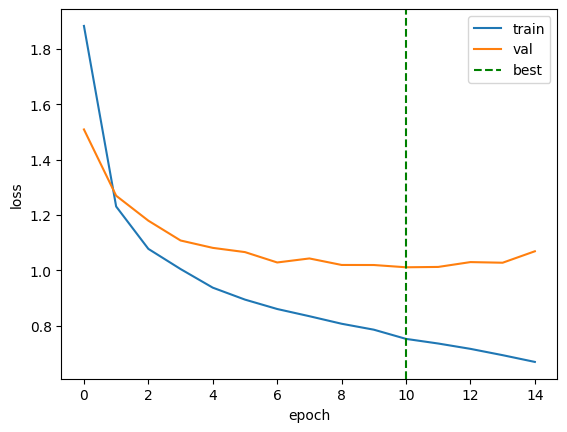

In [8]:
EPOCHS = 20
PATIENCE = 4          # stop if val hasn't improved for this many epochs
MAX_FRAMES = 1500

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for X, S, On, Off, Hard, mask, lens, sexes in loader:
            ms = MAX_FRAMES * HOP
            X, S = X[:, :, :ms].to(device), S[:, :MAX_FRAMES].to(device)
            On, Off = On[:, :MAX_FRAMES].to(device), Off[:, :MAX_FRAMES].to(device)
            mask = mask[:, :MAX_FRAMES].to(device)
            st, on, off = model(X)
            loss, _ = combined_loss(st, on, off, S, On, Off, mask)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item()*X.size(0); n += X.size(0)
            del X, S, On, Off, st, on, off, loss
    torch.cuda.empty_cache()
    return tot/n

hist = {"train": [], "val": []}
best_val = float("inf"); best_epoch = 0; wait = 0

for epoch in range(1, EPOCHS+1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    hist["train"].append(tr); hist["val"].append(va)
    flag = ""
    if va < best_val:
        best_val = va; best_epoch = epoch; wait = 0
        torch.save(model.state_dict(), "best.pt")     # save the best model
        flag = "  <-- best (saved)"
    else:
        wait += 1
    print(f"epoch {epoch:2d} | train {tr:.3f} | val {va:.3f}{flag}")
    if wait >= PATIENCE:
        print(f"early stop: no val improvement for {PATIENCE} epochs")
        break

# restore the best model before evaluating
model.load_state_dict(torch.load("best.pt"))
print(f"\nLoaded best model from epoch {best_epoch} (val {best_val:.3f})")

plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.axvline(best_epoch-1, color="green", ls="--", label="best")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

In [9]:
def predict_probs(loader):
    model.eval()
    On, Off, T, S = [], [], [], []
    with torch.no_grad():
        for X, St, Onb, Offb, Hard, mask, lens, sexes in loader:
            st, on, off = model(X.to(device))
            on  = torch.sigmoid(on).cpu(); off = torch.sigmoid(off).cpu()
            for b in range(X.size(0)):
                L = lens[b].item()
                On.append(on[b, :L].numpy()); Off.append(off[b, :L].numpy())
                T.append(Hard[b, :L].numpy()); S.append(sexes[b])
    return On, Off, T, S

def pick_peaks(prob, thr, min_gap=3):
    peaks = []
    for i in range(len(prob)):
        if prob[i] < thr: continue
        lo, hi = max(0,i-1), min(len(prob), i+2)
        if prob[i] == prob[lo:hi].max() and (not peaks or i-peaks[-1] >= min_gap):
            peaks.append(i)
    return set(peaks)

def event_f1(prob_list, trues, class_id, thr, tol=2):
    tp=fp=fn=0
    for prob, t in zip(prob_list, trues):
        pred = pick_peaks(prob, thr)
        t_idx = list(np.where(t==class_id)[0]); matched=set()
        for ti in t_idx:
            hit=next((pi for pi in pred if abs(pi-ti)<=tol and pi not in matched), None)
            if hit is not None: tp+=1; matched.add(hit)
            else: fn+=1
        fp+=len(pred-matched)
    prec=tp/(tp+fp) if tp+fp else 0.0
    rec =tp/(tp+fn) if tp+fn else 0.0
    f1  =2*prec*rec/(prec+rec) if prec+rec else 0.0
    return prec,rec,f1

# 1) pick best threshold on VALIDATION
vOn, vOff, vT, vS = predict_probs(val_loader)
best_thr, best_f1 = 0.5, 0.0
for thr in [0.2,0.3,0.4,0.5,0.6,0.7,0.8]:
    _,_,f1 = event_f1(vOn, vT, label_to_id["Onset"], thr)
    if f1 > best_f1: best_f1, best_thr = f1, thr
print(f"best threshold on VALIDATION: {best_thr} (val onset F1 {best_f1:.3f})")

# 2) report on TEST using that fixed threshold
On, Off, T, S = predict_probs(test_loader)
S = np.array(S)
pr,rc,f1 = event_f1(On,  T, label_to_id["Onset"],  best_thr)
print(f"\nTEST Onset  @ {best_thr} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f}")
pr,rc,f1 = event_f1(Off, T, label_to_id["Offset"], best_thr)
print(f"TEST Offset @ {best_thr} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f}")

print("\n=== onset F1 by sex (test, fixed threshold) ===")
for sex in ["male","female"]:
    idx=[i for i in range(len(On)) if S[i]==sex]
    if not idx: continue
    pr,rc,f1 = event_f1([On[i] for i in idx],[T[i] for i in idx], label_to_id["Onset"], best_thr)
    print(f"{sex:7s} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f} | recs {len(idx)}")

best threshold on VALIDATION: 0.8 (val onset F1 0.828)

TEST Onset  @ 0.8 | P 0.768 | R 0.824 | F1 0.795
TEST Offset @ 0.8 | P 0.745 | R 0.804 | F1 0.774

=== onset F1 by sex (test, fixed threshold) ===
male    | P 0.713 | R 0.787 | F1 0.748 | recs 143
female  | P 0.849 | R 0.875 | F1 0.862 | recs 109
